A language model is an AI model trained to predict the next word in a sequence of words. LMs are used to analyze text data, understand language patterns, and generate text. Examples of LMs include BERT and CamemBERT.

An Large Language Models(LLM) is a type of LM, but with a significantly larger number of parameters and/or trained on a larger corpus of text data. LLMs are capable of performing a wider range of complex language tasks and generating more sophisticated text. Examples of LLMs include ChatGPT and large versions of CamemBERT

Here, a very simple language model is implemented, which is basically what ChatGPT is, but with a simple LSTM as our decoder. The training goal is to predict the next word in the sequence given the context/sequence.

**What is the input to a Language Model (LM)?**
The input to an LM is just raw text (after tokenization), usually a long stream of tokens, where the model learns to predict the next token given previous ones.
- Input to an LM: a long sequence of tokens (often from all docs clubbed together)
- Chunk into fixed-size windows for training (e.g., 128-token input → predict next 128 tokens)
- Different from NLP models like seq2seq or classification which require explicit input-output pairs.

For eg, in the case of wikitext from Hugging Face, each example is a paragraph (often a line or sentence), and the dataset is structured doc-wise, but for
training a Language Model, we usually flatten all the documents into a single long sequence of tokens. Why because, Language models like GPT or Transformer-XL treat the task as next-token prediction across a continuous stream. There’s no need to reset between documents (unless you're modeling at a document level).

Typical Preprocessing for LM:
- Flatten the dataset:
- Concatenate all text (or tokenized lists) into one long sequence:
["The", "cat", "sat", ..., "on", "the", "mat"]
- Tokenize i.e Convert to IDs using your tokenizer or vocabulary.
- Chunk the token stream into sequences i.e. Break into fixed-length sequences (e.g., 128 tokens):

[t0, t1, ..., t127] → input
[t1, t2, ..., t128] → target

---

| Step            | Input                                        | Target (for loss)     |
| --------------- | -------------------------------------------- | --------------------- |
| Example 1       | `[The, cat, sat, on]`                        | `[cat, sat, on, the]` |
| Numericalized   | `[123, 45, 67, 89]`                          | `[45, 67, 89, 101]`   |
| For LM training | Model learns to predict each `t+1` given `t` |                       |

---

| Task                  | Input                    | Target                          | Notes           |
| --------------------- | ------------------------ | ------------------------------- | --------------- |
| **Language Modeling** | Sequence of tokens       | Next token for each input       | Self-supervised |
| **Translation**       | Source language sentence | Target language sentence        | Supervised      |
| **Classification**    | Sentence / document      | Label (e.g., positive/negative) | Supervised      |
| **NER / POS**         | Sentence                 | Tags per word                   | Supervised      |
| **Summarization**     | Document                 | Shorter version                 | Supervised      |

In short: LMs learn from the data itself (no labels), and the training corpus is often flattened and chunked into fixed-size overlapping or non-overlapping sequences.

Paper that we base on is Regularizing and Optimizing LSTM Language Models, https://arxiv.org/abs/1708.02182

In [4]:
!pip install torchtext torchdata --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 78.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 811.7/811.7 MB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 122.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 108.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 65.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 128.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.5/728.5 MB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 14.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 41.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 20.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/20

In [5]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 97.5 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.21.0+cu124 requires torch==2.6.0, but you have torch 2.2.0+cu118 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
torchtune 0.6.1 requires torchdata==0.11.0, but you have torchdata 0.7.1 which is incompatible.


In [6]:
!pip install portalocker>=2.0.0

In [7]:
!pip install -U datasets huggingface_hub fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 509.3/509.3 kB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 118.9 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.31.2
    Uninstalling huggingface-hub-0.31.2:
      Successfully uninstalled huggingface-hub-0.31.2
  Attempting uninstall: datasets
    Found existing installation: datasets 2.14.4
    Uninstalling datasets-2.14.4:
      Successfully uninstalled datasets-2.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency 

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [1]:
import torch, torchtext, datasets

from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

import torch.nn as nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import torch.optim as optim

from tqdm import tqdm

import time, random, math

SEED = 1234
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

### 1. Load WikiText dataset from huggingface

In [2]:
dataset = datasets.load_dataset(path="Salesforce/wikitext", name="wikitext-2-raw-v1")

In [3]:
dataset

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})

In [4]:
print(dataset["train"][2354]["text"])

 The storm originated in an upper @-@ level low pressure system that moved southeastward from the central Great Plains into the Deep South of the United States . After reaching the southeast Gulf of Mexico , the disturbance underwent cyclogenesis , and the resultant system moved through Florida on December 22 in response to an approaching trough . National Hurricane Center forecaster Jack Beven noted that " as it moved out into the Bahamas , it appeared to take on the characteristics of a tropical storm . " The uncertain nature of the storm prevented the NHC from issuing advisories on it , and forecasters lacked sufficient data to fully assess the cyclone for potential tropical characteristics . The same trough that pushed the storm across Florida had moved to the north , allowing for high pressure to develop in the upper levels of the atmosphere . 



'''
you might notice that sometimes there is no paragraph
and rather an empty string so we will have to care of that later.
'''

In [5]:
print(dataset["train"][2245]["text"])

### 2. Preprocessing

#### 2.1 Tokenization

In [6]:
# use hugging face map and lambda to tokenize all splits at a time

tokenizer = get_tokenizer(tokenizer="basic_english")

tokenization = lambda example, tokenizer: {"tokens" : tokenizer(example["text"])}

dataset = dataset.map(tokenization, remove_columns="text", fn_kwargs={"tokenizer": tokenizer})  # removes the column text after tokenization and we get new column names tokens. Fn_kwarg to pass additional params

dataset

DatasetDict({
    test: Dataset({
        features: ['tokens'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['tokens'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['tokens'],
        num_rows: 3760
    })
})

In [7]:
print(dataset["train"][2354]["tokens"])

['the', 'storm', 'originated', 'in', 'an', 'upper', '@-@', 'level', 'low', 'pressure', 'system', 'that', 'moved', 'southeastward', 'from', 'the', 'central', 'great', 'plains', 'into', 'the', 'deep', 'south', 'of', 'the', 'united', 'states', '.', 'after', 'reaching', 'the', 'southeast', 'gulf', 'of', 'mexico', ',', 'the', 'disturbance', 'underwent', 'cyclogenesis', ',', 'and', 'the', 'resultant', 'system', 'moved', 'through', 'florida', 'on', 'december', '22', 'in', 'response', 'to', 'an', 'approaching', 'trough', '.', 'national', 'hurricane', 'center', 'forecaster', 'jack', 'beven', 'noted', 'that', 'as', 'it', 'moved', 'out', 'into', 'the', 'bahamas', ',', 'it', 'appeared', 'to', 'take', 'on', 'the', 'characteristics', 'of', 'a', 'tropical', 'storm', '.', 'the', 'uncertain', 'nature', 'of', 'the', 'storm', 'prevented', 'the', 'nhc', 'from', 'issuing', 'advisories', 'on', 'it', ',', 'and', 'forecasters', 'lacked', 'sufficient', 'data', 'to', 'fully', 'assess', 'the', 'cyclone', 'for', 

#### 2.2 Numericalization

In [8]:
vocab = build_vocab_from_iterator(dataset["train"]["tokens"], min_freq=3)

In [9]:
len(vocab)

29471

In [10]:
# Add unk and eos and set default index to handle oov(out of vocab)
vocab.insert_token("<unk>", index=0)
vocab.insert_token("<eos>", index=1)
vocab.set_default_index(vocab["<unk>"])
idx2word_mapping = vocab.get_itos()

In [11]:
len(vocab)

29473

In [12]:
idx2word_mapping[0], idx2word_mapping[1], idx2word_mapping[-1]

('<unk>', '<eos>', '攻殻機動隊')

In [13]:
dataset["train"].shape

(36718, 1)

#### 2.3 Numericalization and Flattening

In [14]:
dataset

DatasetDict({
    test: Dataset({
        features: ['tokens'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['tokens'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['tokens'],
        num_rows: 3760
    })
})

In [15]:
dataset["train"]

Dataset({
    features: ['tokens'],
    num_rows: 36718
})

In [16]:
type(dataset["train"]["tokens"]), len(dataset["train"]["tokens"])

(list, 36718)

In [17]:
def numericalize_and_flatten(data, vocab):
    """Flatten and numericalize => we get all docs/sentences flattened into single list for Language Modeling."""
    flattened_ids = []
    for tokens in data["tokens"]:
        tokens.append("<eos>")  # append <eos>
        for token in tokens:
            flattened_ids.extend([vocab[token]])  # extend, not append
    return {"tokens": flattened_ids}

train = dataset["train"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})
val = dataset["validation"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})
test = dataset["test"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})

In [18]:
train, val, test

(Dataset({
     features: ['tokens'],
     num_rows: 2088383
 }),
 Dataset({
     features: ['tokens'],
     num_rows: 218425
 }),
 Dataset({
     features: ['tokens'],
     num_rows: 246514
 }))

In [19]:
type(train["tokens"]), len(train["tokens"])

(list, 2088383)

#### 3. Prepare the DataLoader



In [20]:
def get_batches(dataset, batch_size):
    """Tensor conversion and get batches of even number of tokens"""
    data_tensor = torch.LongTensor(dataset["tokens"])  # shape: (len(tokens),)
    num_batches = data_tensor.shape[0] // batch_size  # gives the evenly divided quotient i.e leaves out the data % batch_size remainder tokens
    # Make the batch evenly and leave out the remaining tokens
    data = data_tensor[:num_batches * batch_size]
    data = data.view(batch_size, num_batches)
    return data

In [21]:
# Get the batches
batch_size = 128

train_batches = get_batches(train, batch_size=batch_size)
val_batches = get_batches(val, batch_size=batch_size)
test_batches = get_batches(test, batch_size=batch_size)

In [22]:
train_batches.shape, val_batches.shape, test_batches.shape

(torch.Size([128, 16315]), torch.Size([128, 1706]), torch.Size([128, 1925]))

Understanding the `get_batches` function:
```python
data = data.view(batch_size, num_batches)
```

This reshapes your long flat token sequence into a 2D tensor with shape **`[batch_size, num_batches]`**. But to understand *why* this is done, let's walk through a **concrete example**.

---

### Imagine This Scenario:

You have tokenized a small dataset:

```python
token_stream = ['I', 'love', 'deep', 'learning', '.', '<eos>',
                'Transformers', 'are', 'great', '.', '<eos>']
```

And your vocabulary maps them to:

```python
vocab = {'I': 0, 'love': 1, 'deep': 2, 'learning': 3, '.': 4,
         '<eos>': 5, 'Transformers': 6, 'are': 7, 'great': 8}
```

Now you numericalize the tokens:

```python
[0, 1, 2, 3, 4, 5, 6, 7, 8, 4, 5]  # total of 11 tokens
```

---

### Suppose:

* `batch_size = 2`

Then:

```python
num_batches = len(data) // batch_size = 11 // 2 = 5
```

We discard the last token (`11 % 2 = 1` leftover), so we take only the first 10 tokens:

```python
data = [0, 1, 2, 3, 4, 5, 6, 7, 8, 4]  # length = 10
```

Now:

```python
data = data.view(2, 5)
```

It reshapes this flat list into a 2D tensor like this:

```
[[ 0,  1,  2,  3,  4],
 [ 5,  6,  7,  8,  4]]
```

---

### What does this mean?

| Batch | Tokens (Time Steps)                |
| ----- | ---------------------------------- |
| 0     | I, love, deep, learning, .         |
| 1     | <eos>, Transformers, are, great, . |

You're treating **each row as a sequence in a batch**, and each column as a **time step**. So during training, the model learns to **predict the next token in the row**.

---

### Why this is done:

This format is ideal for training language models because:

* You can efficiently batch the training.
* At each time step, the model can learn to predict the next token in the sequence *within each row*.

---

This approach assumes that:

* You’re training the model *row-wise*, treating each row as a separate continuous stream of tokens.
* It doesn’t preserve document boundaries — that’s okay for standard LMs, but not for doc-aware models (e.g., BERT with special tokens).

---

```python
data.view(batch_size, num_batches)
```

Reshapes your flat token list into a batch of sequences for efficient training.
**Example**: With `batch_size=2`, `num_batches=5`, and 10 tokens:

```
[0, 1, 2, 3, 4, 5, 6, 7, 8, 4] → [[0,1,2,3,4],
                                  [5,6,7,8,4]]
```



---

#### 3.1 Modified Version of `get_data` - optimized and memory-efficient version

This function that avoids accumulating the entire dataset in a list and instead uses Hugging Face’s IterableDataset and generator logic to prepare token chunks lazily.

```python
import torch
from torch.utils.data import IterableDataset, DataLoader

class LanguageModelingDataset(IterableDataset):
    def __init__(self, dataset, vocab, batch_size, seq_len=128):
        self.dataset = dataset
        self.vocab = vocab
        self.batch_size = batch_size
        self.seq_len = seq_len

    def __iter__(self):
        buffer = []
        for example in self.dataset:
            tokens = example['tokens'] + ['<eos>']
            ids = [self.vocab[token] for token in tokens]
            buffer.extend(ids)

            while len(buffer) >= self.seq_len:
                yield torch.tensor(buffer[:self.seq_len])
                buffer = buffer[self.seq_len:]

def get_dataloader(dataset_split, vocab, batch_size, seq_len=128, shuffle=False):
    lm_dataset = LanguageModelingDataset(dataset_split, vocab, batch_size, seq_len)
    return DataLoader(lm_dataset, batch_size=batch_size, shuffle=shuffle, drop_last=True)
```

---

```python
batch_size = 128
seq_len = 128

train_loader = get_dataloader(tokenized_dataset['train'], vocab, batch_size, seq_len)
valid_loader = get_dataloader(tokenized_dataset['validation'], vocab, batch_size, seq_len)
test_loader  = get_dataloader(tokenized_dataset['test'], vocab, batch_size, seq_len)
```

---

### Usage:

```python
for batch in train_loader:
    print(batch.shape)  # torch.Size([128, 128])
    break
```

---

* Processes examples **streamingly**, no giant memory list.
* Keeps batching efficient and PyTorch-native.


```

why the **optimized `get_data` version** does not do:

```python
num_batches = data.shape[0] // batch_size
data = data[:num_batches * batch_size]
data = data.view(batch_size, num_batches)
```

This old logic:

* **loads all data into memory first**, which is infeasible for large datasets.
* **chops off leftover tokens** that don't evenly divide into batches — meaning data loss.

---

### In the new version (using `IterableDataset` and `DataLoader`):

* **We never load the entire dataset into memory.**
* We **stream** examples and tokenize them chunk-by-chunk (`seq_len` at a time).
* `DataLoader(..., drop_last=True)` handles:

  * grouping examples into batches of `batch_size`
  * dropping incomplete batches if needed
* We **don’t need `num_batches`** because batching is handled dynamically during iteration.

---




### 4. Design the LSTM LM Model

In [23]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, voc_size, embed_dim, num_layers, hidden_dim, dropout):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        self.embedding = nn.Embedding(voc_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, dropout=dropout, batch_first=True)
        self.fc = nn.Linear(hidden_dim, voc_size)   # voc_size
        self.dropout = nn.Dropout(dropout)

    def init_weights(self):
        embed_range_init = 0.1
        others_range_init = 1 / math.sqrt(self.hidden_dim)
        # others_range_init = 1 / torch.sqrt(torch.tensor(self.hidden_dim, dtype=torch.float))
        self.embedding.weight.data.uniform_(-embed_range_init, embed_range_init)  # to have more flexibility in the range. Uniform allows to sample uniformly in the given range
        self.fc.weight.data.uniform_(-embed_range_init, embed_range_init)
        self.fc.bias.data.zero_()
        for i in self.num_layers:
            self.lstm.all_weights[i][0] = torch.FloatTensor(self.embed_dim, self.hidden_dim).uniform_(-others_range_init, others_range_init) # input to hidden
            self.lstm.all_weights[i][1] = torch.FloatTensor(self.hidden_dim, self.hidden_dim).uniform_(-others_range_init, others_range_init) # hidden to hidden
        # for name, param in self.lstm.named_parameters(): # recommended way
        #     if 'weight' in name:
        #         param.data.uniform_(-others_range_init, embed_range_init)
        # elif 'bias' in name:
        #     param.data.zero_()

    def init_hidden_states(self, batch_size, device):
        hidden = torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device)
        cell = torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device)
        return hidden, cell

    def detach_hidden_states(self, hidden, cell):
        hidden = hidden.detach()
        cell = cell.detach()
        return hidden, cell

    def forward(self, src, hidden, cell):
        # src: (bs, seq_len), hidden: (num_layers, bs, hidden_dim)
        embeds = self.dropout(self.embedding(src))  # (bs, seq_len, embed_dim)
        output, (hidden, cell) = self.lstm(embeds, (hidden, cell))
        # h=(num layers * num directions, bs, hidden_dim)
        # c=(num layers * num directions, bs, hidden_dim)
        # output = (bs, seq_len, hidden_dim * num_directions)
        prediction = self.fc(self.dropout(output))   # (bs, seq_len, voc_sizes)
        return prediction, (hidden, cell)

Note: For unidirectional LSTM, each layer’s weight list contains 4 elements:

- weight_ih_l[i] — input-to-hidden weights
- weight_hh_l[i] — hidden-to-hidden weights
- bias_ih_l[i] — input-to-hidden bias
- bias_hh_l[i] — hidden-to-hidden bias

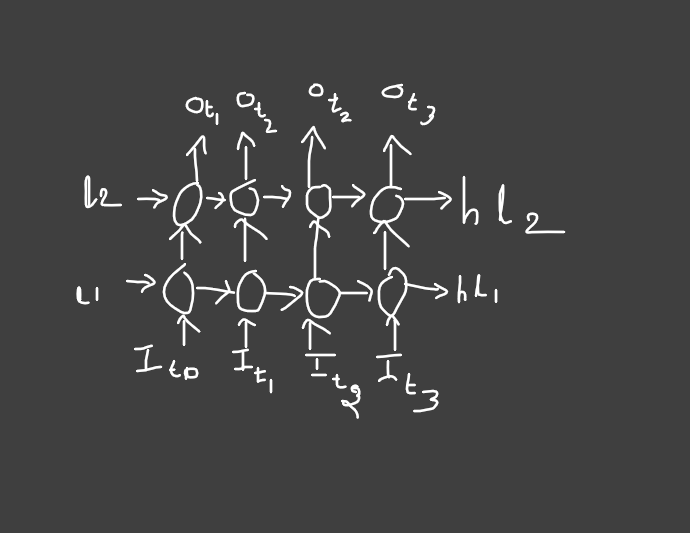

Meaning of **`output`** and **`hidden`** returned by an LSTM, especially in the context of batched language modeling:

```python
output, (hidden, cell) = lstm(input)
```
1. **`output`**: All hidden states from all time steps

   * Shape: **`(seq_len, batch_size, hidden_dim)`**
   * Contains the hidden state **at each time step** for **each example** in the batch.

2. **`hidden`**: Final hidden state from **each layer** (and direction if bidirectional)

   * Shape: **`(num_layers * num_directions, batch_size, hidden_dim)`**
   * This is the last hidden state **for each layer** (not time step!) and **for each batch**.
   * Often used as the summary of the input sequence.

---

### For a Language Model:

If you feed in data shaped like:

```python
input: (seq_len, batch_size)
```

then your LSTM will process each sequence (row-wise in your `view`) as a **separate sequence in the batch**.

So for something like:

```python
data = data.view(batch_size, num_batches).transpose(0, 1)  # shape: (seq_len, batch_size)
```

You’re feeding the LSTM **tokens across time (seq\_len)** and **across batches**.

---

Say you have:

```python
batch_size = 2
seq_len = 5
hidden_dim = 256
num_layers = 2
bidirectional = False
```

Then:

* `input` → `(seq_len=5, batch_size=2)`
* `output` → `(5, 2, 256)`  ← hidden state at each time step
* `hidden` → `(2, 2, 256)`  ← 2 layers, 2 batches

  So:

  ```
  hidden[0] = last hidden state from layer 0
  hidden[1] = last hidden state from layer 1
  ```

> In bidirectional LSTM, the shape would be: `(2 * num_layers, batch_size, hidden_dim)`

---

In Language Modeling:

* `output` is typically passed through a linear + softmax to predict the next token at **each time step**.
* `hidden` is often used for downstream tasks like classification (e.g., final hidden state of last layer).

---

> “Is `hidden` the final sequence from the last batch?”

Not quite.

* `hidden` is the **last hidden state** for **each layer and direction**, for **each sequence in the batch**, **not the full sequence**.
* It’s **not tied to a “last batch”** — it's the result of the LSTM processing **all time steps** in a single batch.



---

### Tiny Example

Let’s say you have the following:

* **Two sequences** of tokens (after numericalization):

  ```
  Sequence A: "I like NLP <eos>"        → [10, 22, 37, 1]
  Sequence B: "Transformers rock <eos>" → [45, 18, 99, 1]
  ```

You want to feed this into an LSTM for **language modeling**.

---

### Step 1: Create the input tensor

```python
batch_size = 2
seq_len = 4

# (seq_len, batch_size)
input = torch.tensor([
    [10, 45],  # timestep 0 → "I", "Transformers"
    [22, 18],  # timestep 1 → "like", "rock"
    [37, 99],  # timestep 2 → "NLP", "<eos>"
    [ 1,  1]   # timestep 3 → "<eos>", "<eos>"
])  # shape: (4, 2)
```

---

### Step 2: Define and run the LSTM

```python
import torch.nn as nn

lstm = nn.LSTM(input_size=embedding_dim, hidden_size=256, num_layers=2)
output, (hidden, cell) = lstm(embedded_input)
```
`embedded_input` is the embedded version of the `input` : `(seq_len, batch_size, embedding_dim)`

---

### What do you get?

#### 🔹 `output`: shape = `(4, 2, 256)`

* For **each time step** (4), and **each sequence** (2), you get the hidden state.
* So:

  * `output[0]`: hidden state after first word in both sequences
  * `output[3]`: hidden state after entire sentence (used to predict next token at each time step)

#### 🔹 `hidden`: shape = `(2, 2, 256)`

* This is for `num_layers=2`, so:

  * `hidden[0]`: final hidden state from **layer 0** for both sequences
  * `hidden[1]`: final hidden state from **layer 1** for both sequences
* Can be thought of as:

  ```python
  hidden[layer][sequence]  # final hidden state after last timestep
  ```

---


| Tensor   | Shape              | What it means                                  |
| -------- | ------------------ | ---------------------------------------------- |
| `input`  | `(seq_len, bs)`    | Tokens arranged by time step                   |
| `output` | `(seq_len, bs, h*directions)` | Hidden state **at each time step**             |
| `hidden` | `(layers*directions, bs, h)`  | Final hidden state for each layer and sequence |

---

To predict the next word at every time step:

```python
next_word_logits = linear(output)  # shape: (seq_len, bs, vocab_size)
```

To summarize a sentence (e.g., for classification):

```python
sentence_vector = hidden[-1]  # final layer's hidden state per sequence
```

hidden captures the final hidden state at the last time step for each sequence in the batch. Since each sequence in the batch has a final state, we have one vector per sequence, not per token.

### 5. Training

One note is that some of the sequences that will be fed to the model may involve parts from different sequences in the original dataset or be a subset of one (depending on the decoding length). For this reason we will reset the hidden state every epoch, this is like assuming that the next batch of sequences is probably always a follow up on the previous in the original dataset.

In [24]:
def get_training_sequences(data, idx, seq_len):
    """
    divide the batches of tokens to batches of sequences to facilitate timesteps dimension i.e temporal stateful training
    """
    src = data[:, idx:idx+seq_len]
    target = data[:, idx+1:idx+1+seq_len] # target simply is ahead of src by 1
    return src, target


**Info on extra slicing in train and val step:**

`get_batches` already creates batches shaped as:

```python
[batch_size, num_tokens]
```

**why are we doing this extra slicing** step in `get_training_sequences`:

We're *batching again* — this time by `seq_len`

In `get_batches`, we prepare the data into shape:

```
data.shape = [batch_size, total_tokens_per_batch]
```

But during training, we're **not using all those tokens at once** — we divide them into **smaller sequences** of length `seq_len` to form mini-batches across time steps, like this:

```python
for idx in range(0, num_tokens, seq_len):
    src = data[:, idx:idx + seq_len]
    target = data[:, idx + 1:idx + seq_len + 1]
```

---

Even though each **row** of `data` (shape `[batch_size, total_tokens]`) contains **all tokens** for a batch, you're **not feeding them all at once** into the model.

Instead, you **slide through them chunk-by-chunk**, using `seq_len` tokens at a time:

```python
for idx in range(0, num_tokens - 1, seq_len):
    src = data[:, idx : idx + seq_len]
    tgt = data[:, idx + 1 : idx + seq_len + 1]
```

### So what does this mean?

* We **split each row** of `data` into multiple **sequence chunks** of length `seq_len`.
* That means:

  * **Each batch** has `batch_size` sequences of length `seq_len`.
  * We move forward `seq_len` tokens at a time — like unrolling the data in time steps.

 Note that in this LM loop, we’re simulating continuous text, so we keep the batch constant and move forward in sequence chunks. You keep the batch dimension fixed: data[:, ...]

The tokens you iterate over are from the same batch — you're just sliding through the sequence. So, this means, for the second iteration of for loop, it does not go to the next batch like in usual tasks, but it slides the sequence of the same batch.

Example:

```
batch_size = 2

data = tensor([[1, 2, 3, 4, 5, 6, 7, 8], [9,10,11,12,13,14,15,16]]) # shape: (2, 8)

seq_len = 3

for idx in range(0, 7, 3):  # 7 = num_tokens - 1
    src = data[:, idx:idx+3]
    print(src)

Output:
tensor([[1, 2, 3],
        [9,10,11]])

tensor([[4, 5, 6],
        [12,13,14]])

tensor([[7, 8, _],   # last slice might be short or trimmed before
        [15,16, _]])

```
Each iteration slides through time, not through batches. The same batch of sequences is used; you're just feeding the model slices of it at a time.

---

### Why not just use all tokens?

Feeding the entire sequence would:

* Be **memory inefficient** (especially with large corpora).
* Prevent **hidden state reuse** over manageable chunks.
* Reduce ability to **truncate backpropagation** (important in RNNs to avoid exploding gradients).

Instead, by processing one `seq_len` chunk at a time and **passing the hidden state forward**, we:

* **Simulate continuity** across the whole text,
* While keeping the **computation tractable**.

---

Fir eg: If you have this data (for `batch_size = 2` and total 10 tokens per row):

```plaintext
Row 1: The cat sat on the mat and purred
Row 2: Dogs bark loud at night always run
```

If `seq_len = 5`, training reads like:

```plaintext
Step 1:
  src: [The cat sat on the]     (5 tokens)
  tgt: [cat sat on the mat]

Step 2:
  src: [mat and purred <pad> <pad>]
  tgt: [and purred <pad> <pad> <pad>]   ← if needed, or skip this if < 5
```

Each `src`/`tgt` pair comes from a **sliding window** across the tokens in that batch row.

---

### Problem: Last few tokens may not fit into a full `seq_len`

Suppose:

* We have `num_tokens = 1001`
* `seq_len = 35`

Then `1001 % 35 = 21`, so the final chunk is incomplete (only 21 tokens). That’s not a full sequence and could cause shape mismatches during training.

---

### Solution: Trim off the leftovers

```python
data = data[:, :num_tokens - (num_tokens - 1) % seq_len]
```

This ensures that:

* The number of time steps (i.e., columns) is **evenly divisible** by `seq_len`.
* We only train on full sequences (e.g., 35 tokens at a time), avoiding misalignment.

The `-1` accounts for 0-based indexing to avoid going out of bounds when slicing `target = data[:, idx+1:...]`.

---

In summary, we **batch twice**:

1. `get_data`: batch by `batch_size`
2. `train`: split into time chunks by `seq_len`

And this line:

```python
data = data[:, :num_tokens - (num_tokens - 1) % seq_len]
```

…ensures all those time-based chunks are evenly sized.

---




In [25]:
def train_step(model, data, optimizer, criterion, bs, seq_len, clip, device):
    model.train()
    epoch_loss = 0.0
    num_tokens = data.shape[-1]  # data: (bs, bunch_of_tokens)

    # Get the batches with same seq length i.e drop/trim tokens that are not a multiple of seq_len (% - gives remainder)
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]  # we need to -1 because we start at 0 # (bs, trimmed_tokens)
    num_tokens = data.shape[-1]

    # reset the hidden every epoch
    hidden, cell = model.init_hidden_states(bs, device)
    for idx in tqdm(range(0, num_tokens - 1, seq_len), desc="Training", leave=False):  # parse chunk by chunk in all the batches(window based parsing)
        optimizer.zero_grad()
        # hidden does not need to be in the computational graph for efficiency
        hidden, cell = model.detach_hidden_states(hidden, cell)

        src, target = get_training_sequences(data, idx, seq_len)  # src, target: (bs, seq_len)
        src, target = src.to(device), target.to(device)
        bs = src.shape[0]
        prediction, (hidden, cell) = model(src, hidden, cell)        # (bs, seq_len, voc_size), (n_layers, bs, hidden_dim), (n_layers, bs, hidden_dim)

        # need to reshape because criterion expects pred to be 2d and target to be 1d
        prediction = prediction.reshape(bs * seq_len, -1)            # (bs * seq_len, voc_size)
        target = target.reshape(-1)                                  # (bs * seq_len)
        loss = criterion(prediction, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item() * seq_len
    return epoch_loss / num_tokens

def val_step(model, data, criterion, bs, seq_len, device):
    model.eval()
    epoch_loss = 0.0
    num_tokens = data.shape[-1]  # data: (bs, bunch_of_tokens)

    # Get the batches with same seq length i.e drop/trim tokens that are not a multiple of seq_len
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]  # we need to -1 because we start at 0 # (bs, trimmed_tokens)
    num_tokens = data.shape[-1]

    # reset the hidden every epoch
    hidden, cell = model.init_hidden_states(bs, device)
    with torch.no_grad():
        for idx in range(0, num_tokens - 1, seq_len):  # parse chunk by chunk in all the batches(window based parsing)
            # hidden does not need to be in the computational graph for efficiency
            hidden, cell = model.detach_hidden_states(hidden, cell)

            src, target = get_training_sequences(data, idx, seq_len)  # src, target: (bs, seq_len)
            src, target = src.to(device), target.to(device)
            bs = src.shape[0]
            prediction, (hidden, cell) = model(src, hidden, cell)       # (bs, seq_len, voc_size), (n_layers, bs, hidden_dim), (n_layers, bs, hidden_dim)
            # need to reshape because criterion expects pred to be 2d and target to be 1d
            prediction = prediction.reshape(bs * seq_len, -1)            # (bs * seq_len, voc_size)
            target = target.reshape(-1)                                  # (bs * seq_len)
            loss = criterion(prediction, target)
            epoch_loss += loss.item() * seq_len
    return epoch_loss / num_tokens


Note: **Truncated Backpropagation Through Time (TBPTT)** is used in LSTM Language Modeling

---

### `init_hidden(batch_size, device)`

This method is called **at the start of each epoch**. It returns **zero-initialized hidden and cell states** for the LSTM:

```python
hidden = torch.zeros(num_layers, batch_size, hidden_dim)
cell   = torch.zeros(num_layers, batch_size, hidden_dim)
```

* Used as the initial hidden state for the first batch.
* Helps the model **start fresh each epoch**.

---

### `detach_hidden(hidden)`

This is used **between batches**, and here's **why it's important**:

#### Why do we `detach()`?

PyTorch dynamically builds the computation graph as operations happen. If we **reuse hidden states from the previous batch without detaching**, the computation graph grows, backpropagating through **all previous batches**, which:

* Is **computationally expensive**.
* **Consumes a lot of memory**.
* Is **unnecessary** if you're training on **independent batches** (as we often do with language modeling).

So, calling `detach()`:

```python
hidden = hidden.detach()
cell = cell.detach()
```

* **Breaks the graph**.
* Treats the previous hidden state as a **constant**, not a variable for gradient computation.
* This makes the new computation **independent** from the old one.

---

| Function          | Purpose                                                                             |
| ----------------- | ----------------------------------------------------------------------------------- |
| `init_hidden()`   | Gives **zero hidden states** for the first batch of an epoch.                       |
| `detach_hidden()` | Prevents backpropagation through time across batch boundaries by cutting the graph. |

---

Think of training like reading a book in chunks:

* `init_hidden()` = Starting a **new book** — you begin with no prior context.
* `detach_hidden()` = Starting a **new chapter** — you remember the last chapter’s theme (hidden state), but you don’t let your thoughts about it affect how you learn this new one (no gradients through previous batch).

---

Note that the **hidden state from one batch is passed to the next batch**, making your model **stateful across batches** during the epoch.

---

* At the **start of an epoch**, you initialize hidden and cell states to zeros via `init_hidden()`.
* For **each batch**, you:

  1. Use the hidden state output from the **previous batch** as the input hidden state.
  2. Run the LSTM on the current batch.
  3. Get new hidden states (the hidden state (and cell state) that is passed from one batch to the next, not the output).
  4. **Detach** them so that the graph doesn’t backprop through earlier batches.

* This way, the LSTM maintains some **temporal continuity** across batches, without unnecessary gradient tracking.

---

### Why do this?

Because in **language modeling**, the **order of tokens matters**. By feeding the hidden state forward, you're letting the model carry **semantic memory** across batches:

```text
Batch 1: "The cat sat on the"
Batch 2: "mat and looked at the"
```

If batch 2 gets the hidden state from batch 1, the model can understand the broader context — helpful for predicting the next token.

---

### Important:
This only makes sense **if your data is sequentially ordered** across batches — which it is in our case because of how we reshaped with:

```python
data.view(batch_size, -1)
```

If your batches were randomly sampled (as in many classification tasks), carrying hidden state across batches wouldn't make sense.

---

Note that, we also have models where the model resets hidden states between batches (stateless training).

**Why multiply loss.item() by seq_len?**

loss.item() is likely an average loss over the sequence length.

Multiplying by seq_len converts it from an average loss per token to a total loss for the entire sequence.

Eg:
If loss.item() = 0.2 (average loss per token) and sequence length = 50 tokens, then total loss for that sequence = 0.2 * 50 = 10.0.

**Why divide by num_tokens?**
num_tokens represents the total number of tokens processed over the whole epoch.

Dividing by num_tokens normalizes the accumulated loss over all sequences back to an average loss per token for the entire epoch.

Putting it all together
You accumulate total loss for each sequence (by multiplying average loss per token by sequence length), sum it over many sequences to get epoch_loss (total loss for the whole epoch)


In [27]:
vocab_size = len(vocab)
vocab_size

29473

In [28]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [29]:
vocab_size = len(vocab)
bs = 128
embed_dim = 1024   # 400 in the paper
hidden_dim = 1024  # 1150 in the paper
num_layers = 2     # 3 in the paper
dropout = 0.65
lr = 1e-3
num_epochs = 50
seq_len = 50 # decoding length
clip = 0.25
best_loss = float("inf")


model = LSTMLanguageModel(vocab_size, embed_dim, num_layers, hidden_dim, dropout).to(device)
model.init_weights()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()
num_params = sum([param.numel() for name, param in  model.named_parameters() if param.requires_grad])
print(f"The model has {num_params:,} trainable parameters")

save_path = f"/content/{model.__class__.__name__}.pt"
# ReduceLRonPlateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=0)

for epoch in range(num_epochs):
    start_time = time.time()
    train_loss = train_step(model, train_batches, optimizer, criterion, bs, seq_len, clip, device)
    val_loss = val_step(model, val_batches, criterion, bs, seq_len, device)

    scheduler.step(val_loss)
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), save_path)
    end_time = time.time()
    elapsed_mins, elapsed_secs = epoch_time(start_time, end_time)

    print(f"Epoch: {epoch+1} | Time: {elapsed_mins}m {elapsed_secs}s\n")
    print(f"\tTrain Perplexity: {math.exp(train_loss):.3f}")
    print(f"\tVal Perplexity: {math.exp(val_loss):.3f}")

The model has 77,183,777 trainable parameters


Epoch: 1 | Time: 0m 29s

	Train Perplexity: 653.763
	Val Perplexity: 324.475


Epoch: 2 | Time: 0m 29s

	Train Perplexity: 360.798
	Val Perplexity: 255.803


Epoch: 3 | Time: 0m 29s

	Train Perplexity: 285.351
	Val Perplexity: 221.519


Epoch: 4 | Time: 0m 29s

	Train Perplexity: 240.411
	Val Perplexity: 199.869


Epoch: 5 | Time: 0m 29s

	Train Perplexity: 209.568
	Val Perplexity: 184.444


... (41 outputs left out)

Epoch: 47 | Time: 0m 29s

	Train Perplexity: 74.458
	Val Perplexity: 132.795


Epoch: 48 | Time: 0m 29s

	Train Perplexity: 74.960
	Val Perplexity: 132.795


Epoch: 49 | Time: 0m 29s

	Train Perplexity: 74.866
	Val Perplexity: 132.796


Epoch: 50 | Time: 0m 28s

	Train Perplexity: 74.904
	Val Perplexity: 132.796


### 6. Testing

In [31]:
model.load_state_dict(torch.load(save_path,  map_location=device))
test_loss = val_step(model, test_batches, criterion, bs, seq_len, device)
print(f'Test Perplexity: {math.exp(test_loss):.3f}')

Test Perplexity: 124.444


### 7. Real-world inference
Here we take the prompt, tokenize, encode and feed it into the model to get the predictions. We then apply softmax while specifying that we want the output due to the last word in the sequence which represents the prediction for the next word. We divide the logits by a temperature value to alter the model’s confidence by adjusting the softmax probability distribution.

Once we have the Softmax distribution, we randomly sample it to make our prediction on the next word. If we get `unk` then we give that another try. Once we get `eos` we stop predicting. Here for sampling, we use multinomial distribution. For suppose, we have the softmax probs of next word in this format for the vocab. [0.1, 0.3, 0.4....voc size] of words in vocab say w1, w2, w3, ...,w_vocsize. In multinomial sampling, we get {w1, w2, w2, w3, w4, w4, w4, w4....} which we call as multinomial distrbution and we can sample words from this dsitribution to attain creativity. Then, We decode the prediction back to strings.

In [36]:
def generate(prompt, model, tokenizer, vocab, max_seq_len, temperature, device, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    tokens = tokenizer(prompt)
    idxs = [vocab[token] for token in tokens]
    bs = 1
    hidden, cell = model.init_hidden_states(bs, device)
    with torch.no_grad():
        for i in range(max_seq_len):
            src = torch.LongTensor([idxs]).to(device)
            prediction, (hidden, cell) = model(src, hidden, cell)  # (bs, seqlen, voc_size)
            # prediction[:, -1]:  (bs, voc_size) => probability of last word in the sequence so far
            probs = torch.softmax(prediction[:, -1] / temperature, dim=-1)
            prediction = torch.multinomial(probs, num_samples=1).item()

            while prediction == vocab["<unk>"]: # if it is unk, we sample again
                prediction = torch.multinomial(probs, num_samples=1).item()
            if prediction == vocab["<eos>"]:   # if it is eos, we stop
                break
            idxs.append(prediction) # autoregressive, appending prediction to our idxs => thus output becomes input.
    idx2word = vocab.get_itos()
    tokens = [idx2word[idx] for idx in idxs]
    return tokens

prompt = "Geoffrey Hinton is"
seed = 0
max_seq_len = 30

# smaller the temperature, more diverse tokens but comes with a tradeoff of less-make-sense sentence
temperatures = [0.5, 0.7, 0.75, 0.8, 1.0]
for t in temperatures:
    tokens = generate(prompt, model, tokenizer, vocab, max_seq_len, t, device, seed=seed)
    print(str(t)+"\n"+' '.join(tokens)+"\n")


0.5
geoffrey <unk> is a member of the old catholic republic . the main altarpiece is the first of the church of christ . the cathedral has been used to be a tradition of

0.7
geoffrey <unk> is a member of his father . it is a supporter of the oldest , the death of the novel . the book ' s depiction is a unique reference ,

0.75
geoffrey <unk> is a reference to the church of the old church movement . the cathedral is the st . louis ' s church . the site ' s status is added to

0.8
geoffrey <unk> is a reference to the church of the old church movement . a theme of the st . louis ' s church of the site ' s status is added to

1.0
geoffrey <unk> is probably based in hell . the general ' s movement was a theme of the st . louis jacques of england . the site ' s department tried to be



In [37]:
temperatures = [0.5, 0.7, 0.75, 0.8, 1.0]
prompt = "Robb Stark and Ramsay Bolton are"
seed = 0
max_seq_len = 30

for t in temperatures:
    tokens = generate(prompt, model, tokenizer, vocab, max_seq_len, t, device, seed=seed)
    print(str(t)+"\n"+' '.join(tokens)+"\n")

0.5
<unk> stark and ramsay bolton are probably used . in the early 20th century , the cathedral is the first of the first known dinosaur of the site .

0.7
<unk> stark and ramsay bolton are probably used . in the early 20th century , the cathedral is the first recorded the structure of the churches , which is believed that the earliest large surviving paintings

0.75
<unk> stark and ramsay bolton are probably commonly depicted .

0.8
<unk> stark and ramsay bolton are probably commonly depicted .

1.0
<unk> stark and ramsay bolton are probably commonly depicted .



In [38]:
temperatures = [0.5, 0.7, 0.75, 0.8, 1.0]
prompt = "Harry Potter is"
seed = 0
max_seq_len = 30

for t in temperatures:
    tokens = generate(prompt, model, tokenizer, vocab, max_seq_len, t, device, seed=seed)
    print(str(t)+"\n"+' '.join(tokens)+"\n")

0.5
harry potter is a reference to the church of the holy church . the church is located on the site of the ganges , which is located in the city of spynie .

0.7
harry potter is a reference to the church of the old church movement . the cathedral is the first recorded building in the 13th century , and the chapterhouse , and is the

0.75
harry potter is a reference to the church of the old church movement . the cathedral is the st . louis ' s church . the site ' s status is added to

0.8
harry potter is a reference to the church of the old church movement . a theme of the st . louis ' s church of the site ' s status is added to

1.0
harry potter is said to be impatient . the general ' s movement was a theme of the st . louis tom joseph , thomas hastings , and a stanza and is later



In [28]:
# Self
import torch, torchtext, datasets

from torchtext.vocab import build_vocab_from_iterator
from torchtext.data.utils import get_tokenizer

import torch.nn as nn
from tqdm import tqdm
import time, math

seed = 1234
torch.manual_seed(seed)
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset
dataset = datasets.load_dataset("SalesForce/wikitext", "wikitext-2-raw-v1")

# Tokenization
tokenizer = get_tokenizer("basic_english")

tokenization = lambda example, tokenizer: {"tokens": tokenizer(example["text"])}
dataset = dataset.map(tokenization, remove_columns=["text"], fn_kwargs={"tokenizer": tokenizer})

# Numericalization
vocab = build_vocab_from_iterator(dataset["train"]["tokens"], min_freq=3)
vocab.insert_token("<unk>", 0)
vocab.insert_token("<eos>", 1)
vocab.set_default_index(vocab["<unk>"])

def numericalize_and_flatten(data, vocab):
    tokens_idxs = []
    for tokens in data["tokens"]:
        tokens.append("<eos>")  # append <eos>
        for token in tokens:
            tokens_idxs.extend([vocab[token]])
    return {"tokens": tokens_idxs}  # has to be same key of the dataset i.e "tokens" for map

train = dataset["train"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})
val = dataset["validation"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})
test = dataset["test"].map(numericalize_and_flatten, batched=True, fn_kwargs={"vocab": vocab})

# Prepare Batches
def prepare_batches(data, batch_size):
    num_batches = len(data) // batch_size  # data_tensor.shape[0]
    data_tensor = torch.LongTensor(data["tokens"])
    trimmed_data = data_tensor[:num_batches *  batch_size]
    trimmed_data = trimmed_data.view(batch_size, num_batches)
    return trimmed_data

# Model
class LSTMLMModel(nn.Module):
    def __init__(self, voc_size, embed_dim, hidden_dim, num_layers, dropout):
        super().__init__()
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.dropout = nn.Dropout(dropout)
        self.embedding = nn.Embedding(voc_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, dropout=dropout, batch_first=True)
        self.fc = nn.Linear(hidden_dim, voc_size)

    def init_weights(self):
        embed_init_range = 0.1
        other_init_range = 1 / math.sqrt(self.hidden_dim)
        self.embedding.weight.data.uniform_(-embed_init_range, embed_init_range)
        self.fc.weight.data.uniform_(-other_init_range, other_init_range)
        self.fc.bias.data.zero_()
        for name, param in self.lstm.named_parameters():
            if "weight" in name:
                param.data.uniform_(-other_init_range, other_init_range)
            elif "bias" in name:
                param.data.zero_()

    def init_hidden(self, batch_size, device):
        hidden = torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device)
        cell = torch.zeros(self.num_layers, batch_size, self.hidden_dim).to(device)
        return hidden, cell

    def detach_hidden(self, hidden):
        hidden, cell = hidden
        hidden = hidden.detach()
        cell = cell.detach()
        return hidden, cell

    def forward(self, src, hidden, cell):
        embeds = self.dropout(self.embedding(src))
        output, (hidden, cell)= self.lstm(embeds, (hidden, cell))
        predictions = self.fc(self.dropout(output))
        return predictions, (hidden, cell)

# Prepare time-step sequences
def prepare_sequences(data, idx, seq_len):
    src = data[:, idx:idx+seq_len]
    target = data[:, idx+1:idx+1+seq_len]
    return src, target

# Train step
def train_step(model, data, seq_len, optimizer, criterion, clip, device):
    epoch_loss = 0.0
    model.train()
    bs = data.shape[0]
    num_tokens = data.shape[-1]
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]
    num_tokens = data.shape[-1]
    hidden, cell = model.init_hidden(bs, device)
    for idx in tqdm(range(0, num_tokens - 1, seq_len), desc="Training", leave=False):
        optimizer.zero_grad()
        hidden, cell = model.detach_hidden((hidden, cell))
        src, target = prepare_sequences(data, idx, seq_len)  # bs, seqlen
        src, target = src.to(device), target.to(device)
        preds, (hidden, cell) = model(src, hidden, cell)
        bs = src.shape[0]
        preds = preds.reshape(bs * seq_len, -1)  # bs, seqlen, voc_size
        target = target.reshape(-1)
        loss = criterion(preds, target)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item() * seq_len
    return epoch_loss / num_tokens

# Val step
def evaluate(model, data, seq_len, criterion, device):
    epoch_loss = 0.0
    model.eval()
    num_tokens = data.shape[-1]
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]
    num_tokens = data.shape[-1]
    bs = data.shape[0]
    hidden, cell = model.init_hidden(bs, device)
    with torch.no_grad():
        for idx in range(0, num_tokens - 1, seq_len):
            hidden, cell = model.detach_hidden((hidden, cell))
            src, target = prepare_sequences(data, idx, seq_len)  # bs, seqlen
            src, target = src.to(device), target.to(device)
            bs = src.shape[0]
            preds, (hidden, cell) = model(src, hidden, cell)
            preds = preds.reshape(bs * seq_len, -1)  # bs, seqlen, voc_size
            target = target.reshape(-1)
            loss = criterion(preds, target)
            epoch_loss += loss.item() * seq_len
    return epoch_loss / num_tokens

def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

# Training
bs = 128
clip = 0.25
dropout = 0.65
vocab_size = len(vocab)
embed_dim = 1024
hidden_dim = 1024
num_layers = 2
num_epochs = 2
lr = 1e-3
seq_len = 50

model = LSTMLMModel(vocab_size, embed_dim, hidden_dim, num_layers, dropout).to(device)
model.init_weights()
print(f"No. of parameters: {sum([param.numel() for param in model.parameters() if param.requires_grad]):,}")
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=0)
criterion = nn.CrossEntropyLoss()

train_batches = prepare_batches(train, bs)
val_batches = prepare_batches(val, bs)
test_batches = prepare_batches(test, bs)

best_loss = float("inf")
save_path = f"/content/{model.__class__.__name__}.pt"

for epoch in range(num_epochs):
    start_time = time.time()
    train_loss = train_step(model, train_batches, seq_len, optimizer, criterion, clip, device)  # training is teacher forcing through time.
    val_loss = evaluate(model, val_batches, seq_len, criterion, device)
    scheduler.step(val_loss)
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), save_path)
    end_time = time.time()
    elapsed_mins, elapsed_secs = epoch_time(start_time, end_time)
    print(f"Epoch: {epoch+1} | Time {elapsed_mins}m {elapsed_secs}s")
    print(f"\tTrain Perplexity: {math.exp(train_loss):.3f} | Val Perplexity: {math.exp(val_loss):.3f}")


# Testing
model.load_state_dict(torch.load(save_path, map_location=device))
test_loss = evaluate(model, test_batches, seq_len, criterion, device)
print(f"\t Test Perplexity: {math.exp(test_loss):.3f}")

# Inference
def generation(prompt, model, vocab, tokenizer, max_seq_len, temperature, device, seed):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    tokens = tokenizer(prompt)
    idxs =  [vocab[token] for token in tokens]
    bs = 1
    hidden, cell = model.init_hidden(bs, device)
    with torch.no_grad():
        for i in range(max_seq_len):
            src = torch.LongTensor([idxs]).to(device)
            preds, (hidden, cell) = model(src, hidden, cell)
            probs = torch.softmax(preds[:, -1] / temperature, dim=-1)
            pred_word_idx = torch.multinomial(probs, num_samples=1).item()
            while pred_word_idx == vocab["<unk>"]:
                pred_word_idx = torch.multinomial(probs, num_samples=1).item()
            if pred_word_idx == vocab["<eos>"]:
                break
            idxs.append(pred_word_idx)  # autoregressive
    idx2word_mapping = vocab.get_itos()
    tokens = [idx2word_mapping[idx] for idx in idxs]
    return tokens

prompt = "Church rennovation"
max_seq_len = 30
temperatures = [0.5, 0.7, 0.75, 0.8, 1.0]
seed = 0
for temp in temperatures:
    tokens = generation(prompt, model, vocab, tokenizer, max_seq_len, temp, device, seed)
    print(f"Tempertaure:{str(temp)}\n\t{' '.join(tokens)}\n")


No. of parameters: 77,183,777


Epoch: 1 | Time 0m 29s
	Train Perplexity: 689.223 | Val Perplexity: 334.276


Epoch: 2 | Time 0m 29s
	Train Perplexity: 345.244 | Val Perplexity: 242.113
	 Test Perplexity: 225.092
Tempertaure:0.5
	church <unk> hide ( panigrahana )

Tempertaure:0.7
	church <unk> rigging swap investigative hell ( the ) ) is a oldman with the friend of st . the condom sample has been accommodated .

Tempertaure:0.75
	church <unk> rigging swap investigative hell is the series of 3 @ , @ 000 copies on the late day . the day of the team ' s stanza and is added

Tempertaure:0.8
	church <unk> rigging swap investigative hell .

Tempertaure:1.0
	church <unk> rigging swap investigative hell .



In [24]:
print(f"LSTM type: {type(model.lstm)}")

LSTM type: <class 'torch.nn.modules.rnn.LSTM'>
